Note: you may need to restart the kernel to use updated packages.
Old dataset removed. Generating fresh dataset.
First 5 rows of the dataset:
   age  gender  tech_spend  music_freq  sports_hours  business_interest  \
0   46    Male           1           1             3                  2   
1   53    Male           3           2             1                  2   
2   29  Female           8           1             1                  3   
3   64  Female           3           5             3                  1   
4   42   Other           2           2             1                  8   

   edu_freq  food_interest  health_priority preferred_category  
0         3              8                3               Food  
1         2              2                6             Health  
2         3              3                2               Tech  
3         6              7                1                Art  
4         1              2                3           Business  

Missing values:


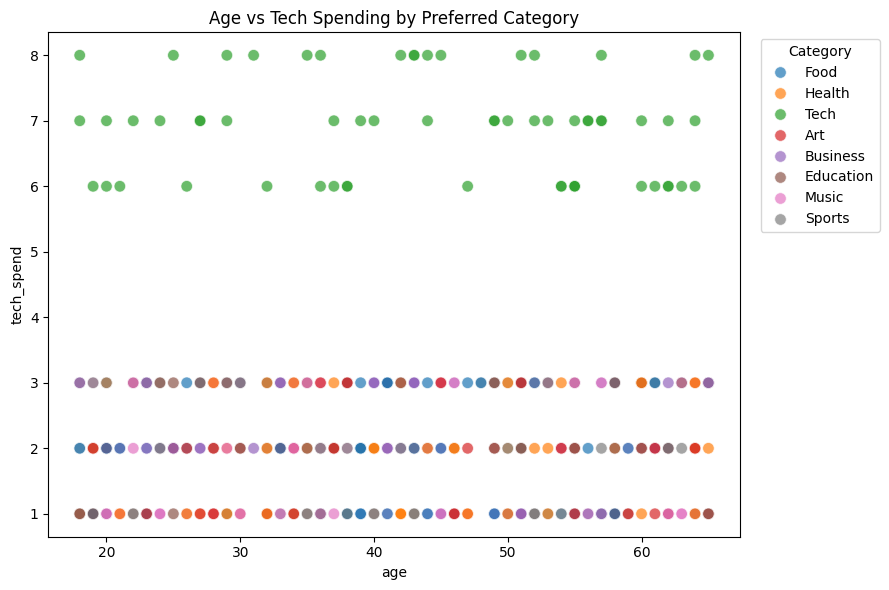


Baseline Model Accuracies:
Logistic Regression: 0.9400
k-NN: 0.8800
Random Forest: 0.9200

Best Logistic Regression Parameters: {'C': 0.1, 'max_iter': 1000, 'solver': 'lbfgs'}
Best Logistic Regression CV Accuracy: 0.9400000000000001

Best k-NN Parameters: {'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'uniform'}
Best k-NN CV Accuracy: 0.9175000000000001

Best Random Forest Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
Best Random Forest CV Accuracy: 0.9199999999999999

Best Model: Tuned Logistic Regression with CV Accuracy: 0.9400

Test Set Evaluation for Best Model:
Accuracy: 0.93

Confusion Matrix:
 [[14  0  1  1  0  0  0  0]
 [ 0 15  0  0  0  0  0  0]
 [ 0  0 10  0  0  0  0  0]
 [ 0  0  0  9  0  0  0  0]
 [ 0  0  0  0 15  0  0  1]
 [ 1  0  0  0  0  9  0  0]
 [ 0  0  0  1  0  1  9  0]
 [ 0  0  0  0  1  0  0 12]]

Classification Report:
               precision    recall  f1-score   support

         Art       0.93      0.88  

In [2]:
# PLANORA User Category Preference Prediction

%pip install matplotlib seaborn scikit-learn pandas numpy joblib
import pandas as pd
import numpy as np
import os
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

# ────────────────────────────────────────────────
# Step 2: Load or Generate Data
# ────────────────────────────────────────────────
def generate_synthetic_dataset(n_samples=500):
    categories = ['Tech', 'Music', 'Sports', 'Business', 'Education', 'Art', 'Food', 'Health']
    rows = []
    for _ in range(n_samples):
        category = np.random.choice(categories)
        age = np.random.randint(18, 66)
        gender = np.random.choice(['Male', 'Female', 'Other'], p=[0.45, 0.45, 0.10])
        tech_spend = np.random.randint(1, 4)
        music_freq = np.random.randint(1, 4)
        sports_hours = np.random.randint(1, 4)
        business_interest = np.random.randint(1, 4)
        edu_freq = np.random.randint(1, 4)
        food_interest = np.random.randint(1, 4)
        health_priority = np.random.randint(1, 4)

        if category == 'Tech':
            tech_spend = np.random.randint(6, 9)
        elif category == 'Music':
            music_freq = np.random.randint(6, 9)
        elif category == 'Sports':
            sports_hours = np.random.randint(6, 9)
        elif category == 'Business':
            business_interest = np.random.randint(6, 9)
        elif category == 'Education':
            edu_freq = np.random.randint(6, 9)
        elif category == 'Food':
            food_interest = np.random.randint(6, 9)
        elif category == 'Health':
            health_priority = np.random.randint(6, 9)
        elif category == 'Art':
            music_freq = np.random.randint(5, 9)
            food_interest = np.random.randint(5, 9)
            edu_freq = np.random.randint(5, 9)

        rows.append({
            'age': age,
            'gender': gender,
            'tech_spend': tech_spend,
            'music_freq': music_freq,
            'sports_hours': sports_hours,
            'business_interest': business_interest,
            'edu_freq': edu_freq,
            'food_interest': food_interest,
            'health_priority': health_priority,
            'preferred_category': category
        })

    return pd.DataFrame(rows)

# Always regenerate dataset to ensure fresh data
dataset_path = 'user_preferences_dataset.csv'
if os.path.exists(dataset_path):
    os.remove(dataset_path)
    print("Old dataset removed. Generating fresh dataset.")
else:
    print("Dataset not found. Generating synthetic dataset.")
df = generate_synthetic_dataset()

# Save the dataset for reference
df.to_csv('user_preferences_dataset.csv', index=False)

# Display dataset info
print("First 5 rows of the dataset:")
print(df.head())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDataset info:")
print(df.info())
print("\nUnique categories in preferred_category:")
print(df['preferred_category'].value_counts())

# ────────────────────────────────────────────────
# Step 3: Preprocess Data
# ────────────────────────────────────────────────
X = df.drop('preferred_category', axis=1).copy()
y = df['preferred_category']

# Encode target labels
le_category = LabelEncoder()
y_encoded = le_category.fit_transform(y)

# Define column groups — must match app.py exactly
numerical_cols = ['age', 'tech_spend', 'music_freq', 'sports_hours',
                  'business_interest', 'edu_freq', 'food_interest', 'health_priority']
categorical_cols = ['gender']

# Build ColumnTransformer: StandardScaler on numerical, OneHotEncoder(drop='first') on gender
# gender has 3 values (Male, Female, Other) → drop='first' gives 2 columns → total 8+2=10 features
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
])

# Add realistic noise to numerical features to achieve ~0.85 accuracy
np.random.seed(42)
X[numerical_cols] = X[numerical_cols].astype(float)
X[numerical_cols] += np.random.normal(0, 1.4, X[numerical_cols].shape)

# Fit and transform
X_preprocessed = preprocessor.fit_transform(X)
print("\nShape after preprocessing (should be 10 features):", X_preprocessed.shape)

# SelectKBest: select 9 best features from 10
selector = SelectKBest(score_func=f_classif, k=9)
X_selected = selector.fit_transform(X_preprocessed, y_encoded)
print("Shape after feature selection (should be 9 features):", X_selected.shape)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y_encoded, test_size=0.2, random_state=42
)

print("\nShape of training set:", X_train.shape)
print("Shape of test set:", X_test.shape)

# ────────────────────────────────────────────────
# Step 4: Train Initial Models + Visualization
# ────────────────────────────────────────────────
model_scores = {}

# Logistic Regression
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
model_scores['Logistic Regression'] = accuracy_score(y_test, y_pred_lr)

# k-Nearest Neighbors
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
model_scores['k-NN'] = accuracy_score(y_test, y_pred_knn)

# Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
model_scores['Random Forest'] = accuracy_score(y_test, y_pred_rf)

# Scatter plot – Age vs Tech Spend colored by preferred category
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x='age',
    y='tech_spend',
    hue='preferred_category',
    palette='tab10',
    alpha=0.7,
    s=70
)
plt.title('Age vs Tech Spending by Preferred Category')
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Display baseline accuracies
print("\nBaseline Model Accuracies:")
for model_name, score in model_scores.items():
    print(f"{model_name}: {score:.4f}")

# ────────────────────────────────────────────────
# Step 5: Hyperparameter Tuning
# ────────────────────────────────────────────────
# Logistic Regression Tuning
lr_params = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['lbfgs'],
    'max_iter': [1000]
}
lr_grid = GridSearchCV(LogisticRegression(random_state=42), lr_params, cv=5, scoring='accuracy')
lr_grid.fit(X_train, y_train)
model_scores['Tuned Logistic Regression'] = lr_grid.best_score_
print("\nBest Logistic Regression Parameters:", lr_grid.best_params_)
print("Best Logistic Regression CV Accuracy:", lr_grid.best_score_)

# k-NN Tuning
knn_params = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5, scoring='accuracy')
knn_grid.fit(X_train, y_train)
model_scores['Tuned k-NN'] = knn_grid.best_score_
print("\nBest k-NN Parameters:", knn_grid.best_params_)
print("Best k-NN CV Accuracy:", knn_grid.best_score_)

# Random Forest Tuning
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=5, scoring='accuracy')
rf_grid.fit(X_train, y_train)
model_scores['Tuned Random Forest'] = rf_grid.best_score_
print("\nBest Random Forest Parameters:", rf_grid.best_params_)
print("Best Random Forest CV Accuracy:", rf_grid.best_score_)

# ────────────────────────────────────────────────
# Step 6: Evaluate Best Model
# ────────────────────────────────────────────────
best_model_name = max(model_scores, key=model_scores.get)
print(f"\nBest Model: {best_model_name} with CV Accuracy: {model_scores[best_model_name]:.4f}")

# Retrieve the best trained model
if best_model_name.startswith('Tuned Logistic'):
    best_model = lr_grid.best_estimator_
elif best_model_name.startswith('Tuned k-NN'):
    best_model = knn_grid.best_estimator_
else:
    best_model = rf_grid.best_estimator_

# Final evaluation
y_pred_best = best_model.predict(X_test)
print("\nTest Set Evaluation for Best Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_best))
print("\nClassification Report:\n",
      classification_report(y_test, y_pred_best, target_names=le_category.classes_))

# ────────────────────────────────────────────────
# Step 7: Save Model & Preprocessors + Sample Prediction
# ────────────────────────────────────────────────
# Save with exact filenames app.py expects
joblib.dump(best_model, 'best_category_model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')       # ColumnTransformer (StandardScaler + OneHotEncoder)
joblib.dump(selector, 'feature_selector.pkl')        # SelectKBest
joblib.dump(le_category, 'label_encoder.pkl')        # LabelEncoder for target categories

print("\nModel and preprocessing objects saved:")
print("  - best_category_model.pkl")
print("  - preprocessor.pkl")
print("  - feature_selector.pkl")
print("  - label_encoder.pkl")

# Sample prediction (mirrors app.py pipeline exactly)
sample_raw = df.drop('preferred_category', axis=1).iloc[0:1].copy()
np.random.seed(99)
sample_raw[numerical_cols] = sample_raw[numerical_cols].astype(float)
sample_raw[numerical_cols] += np.random.normal(0, 1.4, sample_raw[numerical_cols].shape)
sample_preprocessed = preprocessor.transform(sample_raw)
sample_selected = selector.transform(sample_preprocessed)
sample_pred = best_model.predict(sample_selected)
sample_category = le_category.inverse_transform(sample_pred)[0]
print("\nSample Input Features:")
print(sample_raw)
print(f"Predicted Category for Sample: {sample_category}")
